# Compact Exact Algorithm Comparison

This notebook compares five fixed-budget sequential discrimination strategies on the compact Problem 2 benchmark: Exhaustive search, Greedy, Tree-aware heuristic, Uniform, and Random.

All comparisons use the surrogate tree error optimized by the algorithms. Each method is evaluated on the same generated cases and sensor budgets, so the reported gaps and runtimes are paired by problem instance.

The notebook reports two quantities needed for the paper:

1. Surrogate-error gap relative to the Exhaustive-search solution.
2. Runtime reduction relative to Exhaustive search.

Use `RUN_SCOPE = "test"` in the settings cell for the balanced pilot run, or `RUN_SCOPE = "full"` for the full compact data set.


In [5]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Resolve paths whether the notebook is launched from the repository root or this folder.
working_directory = Path.cwd().resolve()
PROJECT_DIRECTORY = (
    working_directory / "min-error-sequential"
    if (working_directory / "min-error-sequential").is_dir()
    else working_directory
)
MODULE_DIRECTORY = PROJECT_DIRECTORY
SOURCE_DIRECTORY = PROJECT_DIRECTORY / "src"
if str(SOURCE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIRECTORY))

# Reload algorithm code first so comparison_analysis sees the latest heuristic signature.
import heuristic
heuristic = importlib.reload(heuristic)

# Reload local analysis code when this notebook is already open.
import comparison_analysis
comparison_analysis = importlib.reload(comparison_analysis)
field_family_summary = comparison_analysis.field_family_summary
load_paired_results = comparison_analysis.load_paired_results
overall_error_curve_summary = comparison_analysis.overall_error_curve_summary
paired_summary = comparison_analysis.paired_summary
runtime_by_k_summary = comparison_analysis.runtime_by_k_summary
run_paired_dataset = comparison_analysis.run_paired_dataset

print("Project directory:", PROJECT_DIRECTORY)
print("Source directory:", SOURCE_DIRECTORY)


Project directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential
Source directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/src


## Run Settings

Set `RUN_SCOPE = "test"` for the balanced pilot run or `RUN_SCOPE = "full"` for all compact records. The test scope uses 10 replicates from each field-family, $K$, and $M$ cell, giving 180 cases per dataset. The full scope uses all 2,520 cases per dimension and is much slower because every case also runs Exhaustive search.


In [6]:
# Run both spatial benchmark datasets. Each dataset contains 2,520 cases.
DATASETS = ["compact_benchmark_1d", "compact_benchmark_2d"]

# Switch here: "test" runs 180 balanced cases; "full" runs all 2,520 cases per dataset.
RUN_SCOPE = "test"
if RUN_SCOPE not in {"test", "full"}:
    raise ValueError('RUN_SCOPE must be "test" or "full"')

# None keeps every replicate; 10 gives the balanced test subset.
REPLICATES_PER_CELL = None if RUN_SCOPE == "full" else 10

PROGRESS_EVERY = 100 if RUN_SCOPE == "full" else 25

# Save result tables and figures under this directory.
RESULTS_ROOT = MODULE_DIRECTORY / "results" / "algorithm_comparison_compact"

print("Run scope:", RUN_SCOPE)
print("Cases per dataset:", "2,520" if RUN_SCOPE == "full" else "180")
print("Progress interval:", PROGRESS_EVERY, "cases")
print("Results directory:", RESULTS_ROOT)


Run scope: test
Cases per dataset: 180
Progress interval: 25 cases
Results directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/algorithm_comparison_compact


## Algorithm configuration



In [7]:
# Exhaustive search has no optional tuning parameters.
OPTIMAL_PARAMETERS = {}

# The existing greedy method has no optional tuning parameters.
GREEDY_PARAMETERS = {}

# Configure tree construction, local allocation search, and initialization.
TREE_AWARE_PARAMETERS = {
    "beam_width": 3,  # Number of partial trees kept after each expansion.
    "max_iterations": 3,  # Maximum allocation-search iterations.
    "improvement_threshold": 1e-5,  # Required reduction in final error.
    "initialization": "greedy",  # Greedy allocation followed by tree-aware refinement.
    "move_shortlist_size": 1,  # Expensive tree rebuilds per iteration.
}

# Use the same seed as the heuristic's near-uniform starting allocation.
UNIFORM_PARAMETERS = {
    "random_seed": 0,
}

# Reproduce case-specific random allocations and decision trees.
RANDOM_PARAMETERS = {
    "random_seed": 0,
}

print("Optimal parameters:", OPTIMAL_PARAMETERS)
print("Greedy parameters:", GREEDY_PARAMETERS)
print("Heuristic parameters:", TREE_AWARE_PARAMETERS)
print("Uniform parameters:", UNIFORM_PARAMETERS)


Optimal parameters: {}
Greedy parameters: {}
Heuristic parameters: {'beam_width': 3, 'max_iterations': 3, 'improvement_threshold': 1e-05, 'initialization': 'greedy', 'move_shortlist_size': 1}
Uniform parameters: {'random_seed': 0}


## Run all five algorithms



In [8]:
# Keep each dimension separate so the plots can show 1D and 2D side by side.
records_by_dataset = {}
for dataset in DATASETS:
    display(Markdown(f"### Running `{dataset}`"))
    # Run all algorithms using the same cases and budgets.
    records_by_dataset[dataset] = run_paired_dataset(
        dataset,  # Name of the input benchmark directory.
        replicates_per_cell=REPLICATES_PER_CELL,  # None means all cases.
        results_root=RESULTS_ROOT,  # Base directory for comparison results.
        optimal_parameters=OPTIMAL_PARAMETERS,
        greedy_parameters=GREEDY_PARAMETERS,
        tree_aware_parameters=TREE_AWARE_PARAMETERS,
        uniform_parameters=UNIFORM_PARAMETERS,
        random_parameters=RANDOM_PARAMETERS,
        progress_every=PROGRESS_EVERY,
    )


### Running `compact_benchmark_1d`

compact_benchmark_1d: completed case 1/180 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 25/180 (gaussian, K=4, M=3)
compact_benchmark_1d: completed case 50/180 (gaussian, K=5, M=3)
compact_benchmark_1d: completed case 75/180 (sinusoidal, K=3, M=4)
compact_benchmark_1d: completed case 100/180 (sinusoidal, K=4, M=4)
compact_benchmark_1d: completed case 125/180 (quadratic, K=3, M=3)
compact_benchmark_1d: completed case 150/180 (quadratic, K=4, M=3)
compact_benchmark_1d: completed case 175/180 (quadratic, K=5, M=4)
compact_benchmark_1d: completed case 180/180 (quadratic, K=5, M=4)


### Running `compact_benchmark_2d`

compact_benchmark_2d: completed case 1/180 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 25/180 (gaussian, K=4, M=3)
compact_benchmark_2d: completed case 50/180 (gaussian, K=5, M=3)
compact_benchmark_2d: completed case 75/180 (sinusoidal, K=3, M=4)
compact_benchmark_2d: completed case 100/180 (sinusoidal, K=4, M=4)
compact_benchmark_2d: completed case 125/180 (quadratic, K=3, M=3)
compact_benchmark_2d: completed case 150/180 (quadratic, K=4, M=3)
compact_benchmark_2d: completed case 175/180 (quadratic, K=5, M=4)
compact_benchmark_2d: completed case 180/180 (quadratic, K=5, M=4)


## Paired Surrogate-Error Summary

This table compares each approximate method against the surrogate-exhaustive solution on paired runs. Error gaps are `method surrogate error - Exhaustive surrogate error`; smaller values are better. Exact-error matches count runs where the method reaches the same surrogate error as Exhaustive within the configured tolerance.


In [ ]:
# Start a Markdown table for the main quality and runtime statistics.
summary_lines = [
    "| Dataset | Method | Cases | Paired runs | Mean surrogate-error gap | Maximum surrogate-error gap | Exact surrogate-error matches | Median speedup |",
    "|---|---|---:|---:|---:|---:|---:|---:|",
]
for dataset, records in records_by_dataset.items():
    # Calculate statistics from paired runs within one spatial dimension.
    summary = paired_summary(records)
    # The prefix selects the matching values from the summary dictionary.
    for method, prefix in (
        ("Greedy", "greedy"),
        ("Heuristic", "tree_aware"),
        ("Uniform", "uniform"),
        ("Random", "random"),
    ):
        summary_lines.append(
            f"| {dataset} | {method} | {summary['cases']} | {summary['runs']} | "
            f"{summary[f'{prefix}_mean_gap']:.4f} | "
            f"{summary[f'{prefix}_maximum_gap']:.4f} | "
            f"{100 * summary[f'{prefix}_exact_match_rate']:.1f}% | "
            f"{summary[f'{prefix}_median_speedup']:.1f}x |"
        )
# Render the completed table inside the notebook.

display(Markdown("\n".join(summary_lines)))


## Overall Surrogate-Error Curve Summary

Each row is one point in the overall mean-error curves. The error columns are surrogate final errors from the fixed decision trees. Gap cells show absolute error reductions and percentage reductions; positive values mean the second method is better.


In [ ]:
curve_summary_lines = [
    r"| Dimension | Budget level | Mean $N/N_{\min}^{opt}$ | Optimal mean surrogate error | Greedy mean surrogate error | Heuristic mean surrogate error | Uniform mean surrogate error | Random mean surrogate error | Optimal reduction from Greedy | Optimal reduction from Heuristic | Heuristic reduction from Greedy |",
    "|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|",
]
for records in records_by_dataset.values():
    for row in overall_error_curve_summary(records):
        curve_summary_lines.append(
            f"| {row['dimension']} | {row['budget_level']} | "
            f"{row['mean_budget_fraction']:.3f} | "
            f"{row['optimal_mean_error']:.4f} | "
            f"{row['greedy_mean_error']:.4f} | "
            f"{row['heuristic_mean_error']:.4f} | "
            f"{row['uniform_mean_error']:.4f} | "
            f"{row['random_mean_error']:.4f} | "
            f"{row['optimal_from_greedy']:.4f} "
            f"({row['optimal_from_greedy_percent']:.1f}%) | "
            f"{row['optimal_from_heuristic']:.4f} "
            f"({row['optimal_from_heuristic_percent']:.1f}%) | "
            f"{row['heuristic_from_greedy']:.4f} "
            f"({row['heuristic_from_greedy_percent']:.1f}%) |"
        )

display(Markdown("\n".join(summary_lines)))
display(Markdown("\n".join(curve_summary_lines)))


## Runtime summary by number of fields



In [ ]:
runtime_summary_lines = [
    "| Dimension | $K$ | Optimal median runtime (s) | Greedy runtime (speedup) | Heuristic runtime (speedup) | Uniform runtime (speedup) | Random runtime (speedup) |",
    "|---|---:|---:|---:|---:|---:|---:|",
]
for records in records_by_dataset.values():
    for row in runtime_by_k_summary(records):
        runtime_summary_lines.append(
            f"| {row['dimension']} | {row['K']} | "
            f"{row['optimal_median_seconds']:.6f} | "
            f"{row['greedy_median_seconds']:.6f} "
            f"({row['greedy_median_speedup']:.1f}x) | "
            f"{row['heuristic_median_seconds']:.6f} "
            f"({row['heuristic_median_speedup']:.1f}x) | "
            f"{row['uniform_median_seconds']:.6f} "
            f"({row['uniform_median_speedup']:.1f}x) | "
            f"{row['random_median_seconds']:.6f} "
            f"({row['random_median_speedup']:.1f}x) |"
        )

display(Markdown("\n".join(summary_lines)))
display(Markdown("\n".join(runtime_summary_lines)))


## Error-gap summary by field family



In [ ]:
family_summary_lines = [
    "| Dimension | Field family | Greedy mean surrogate-error gap | Heuristic mean surrogate-error gap | Uniform mean surrogate-error gap | Random mean surrogate-error gap | Heuristic gap reduction from Greedy |",
    "|---|---|---:|---:|---:|---:|---:|",
]
for records in records_by_dataset.values():
    for row in field_family_summary(records):
        family_summary_lines.append(
            f"| {row['dimension']} | {row['field_family']} | "
            f"{row['greedy_mean_gap']:.4f} | "
            f"{row['heuristic_mean_gap']:.4f} | "
            f"{row['uniform_mean_gap']:.4f} | "
            f"{row['random_mean_gap']:.4f} | "
            f"{row['heuristic_gap_reduction']:.4f} "
            f"({row['heuristic_gap_reduction_percent']:.1f}%) |"
        )

display(Markdown("\n".join(summary_lines)))
display(Markdown("\n".join(family_summary_lines)))


## Comparison Plots

These figures use surrogate final error, because this notebook compares algorithms under the objective used for optimization.

1. **Mean surrogate-error curves:** quality-budget tradeoff separately for each $K$.
2. **Overall mean surrogate-error curves:** 1D and 2D summaries averaged across all included $K$, $M$, and field families.
3. **Runtime speedup:** computational benefit relative to exhaustive search.
4. **Surrogate-error gap by field family:** Gaussian, sinusoidal, and quadratic fields.


## Mean surrogate-error curves

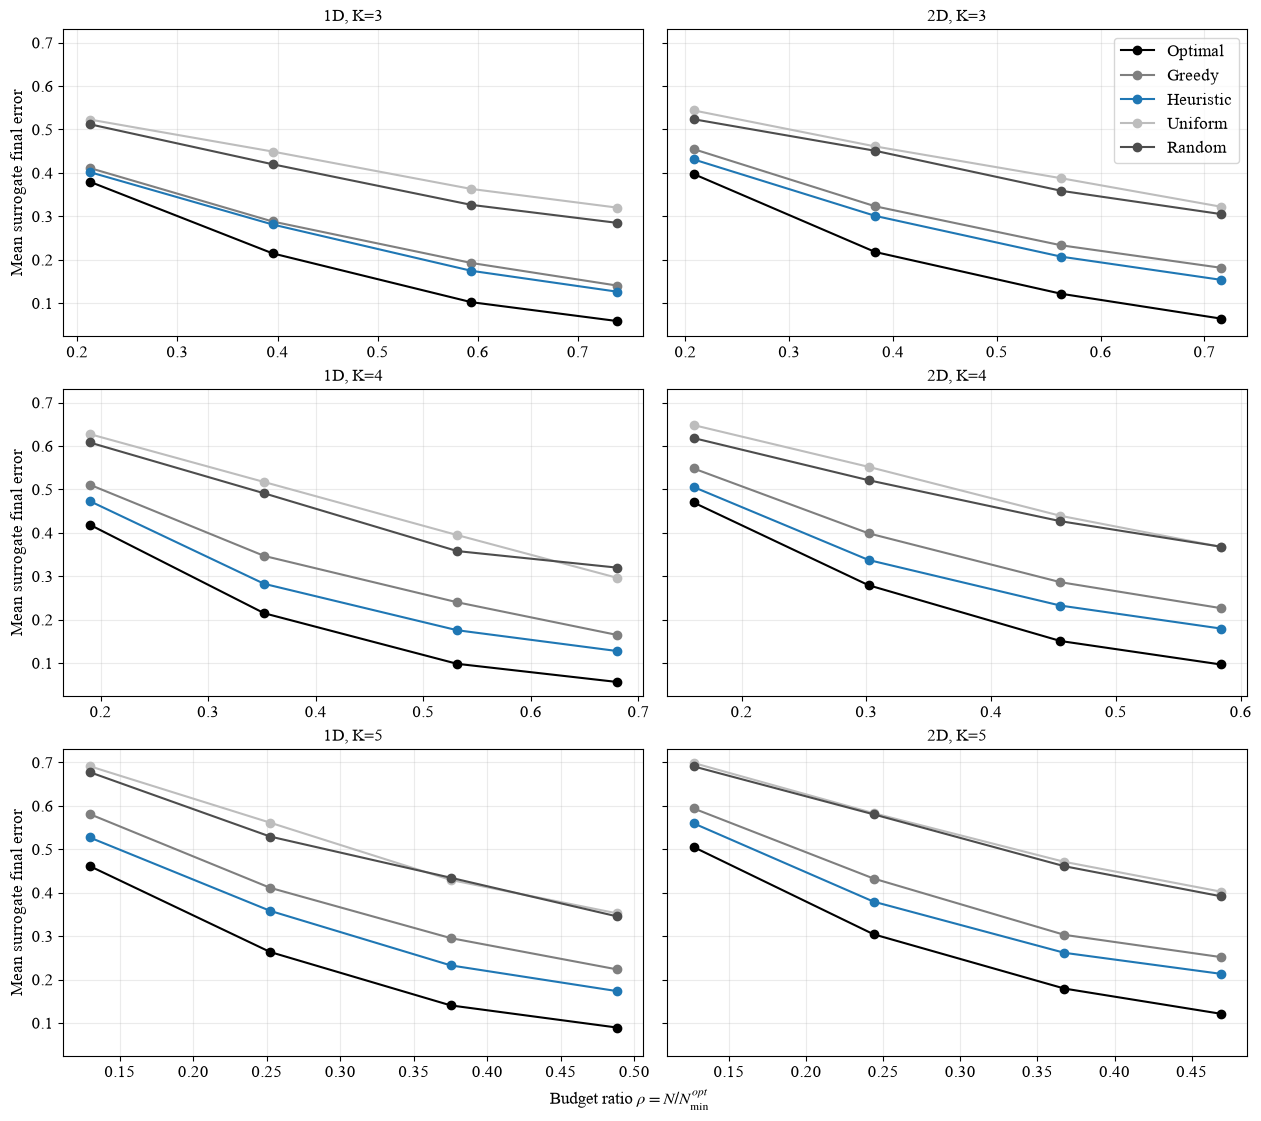

## Overall mean surrogate-error curves

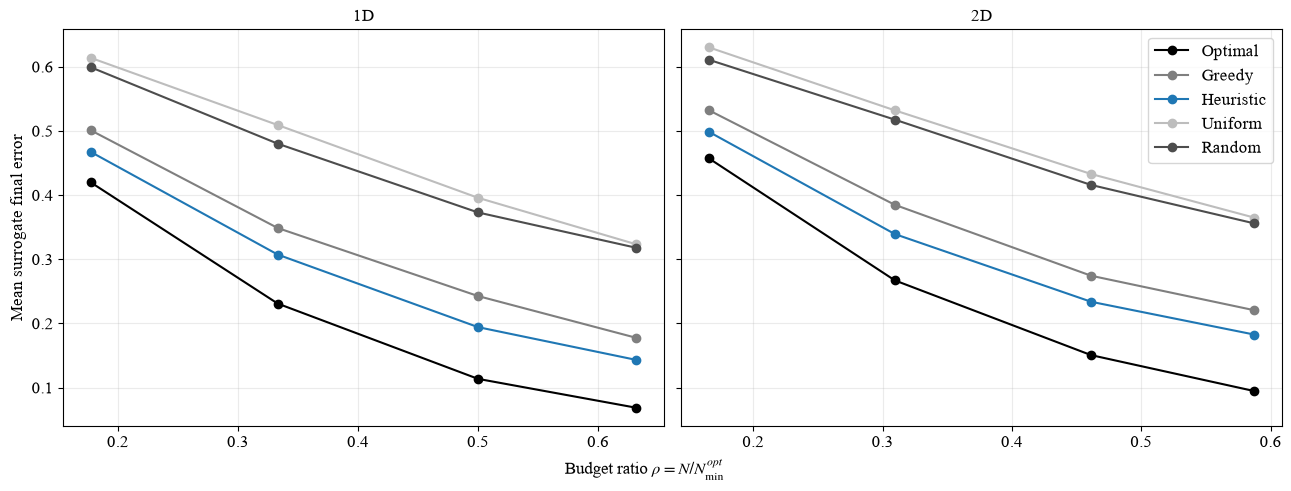

## Runtime speedup

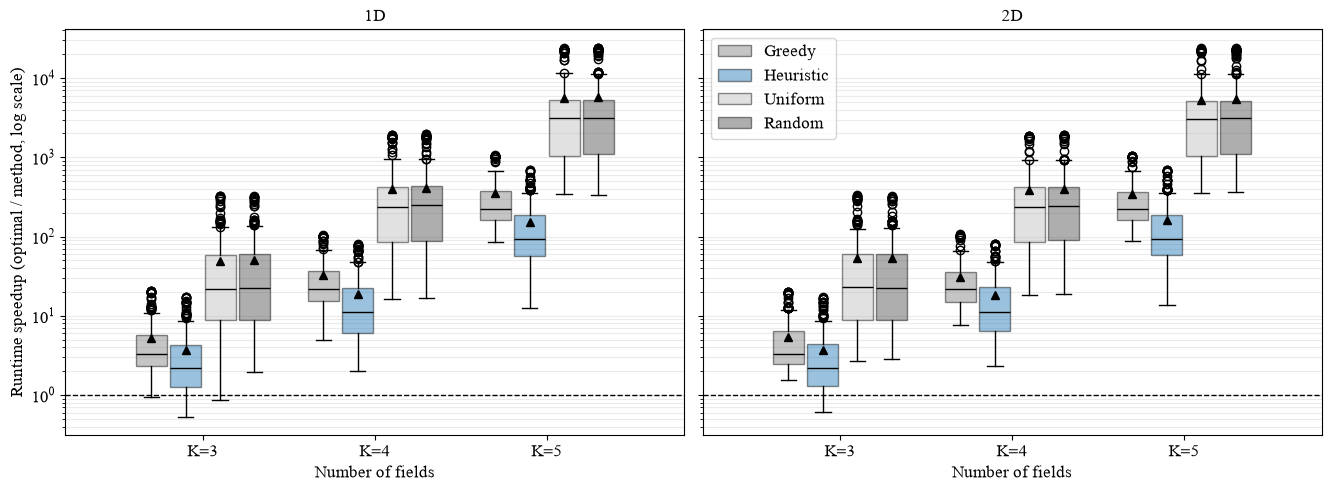

## Surrogate-error gap by field family

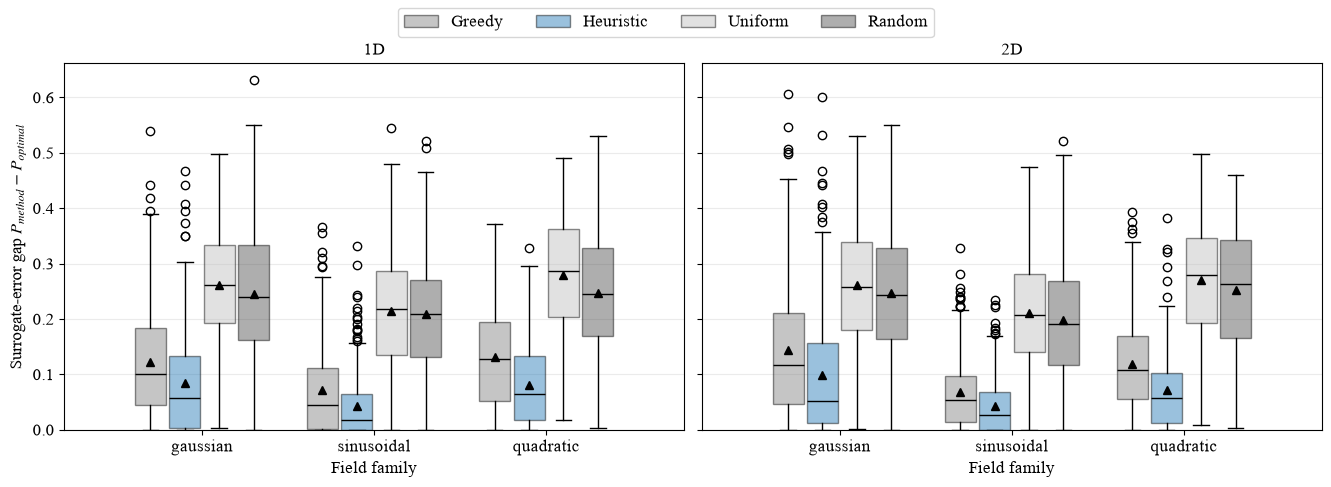

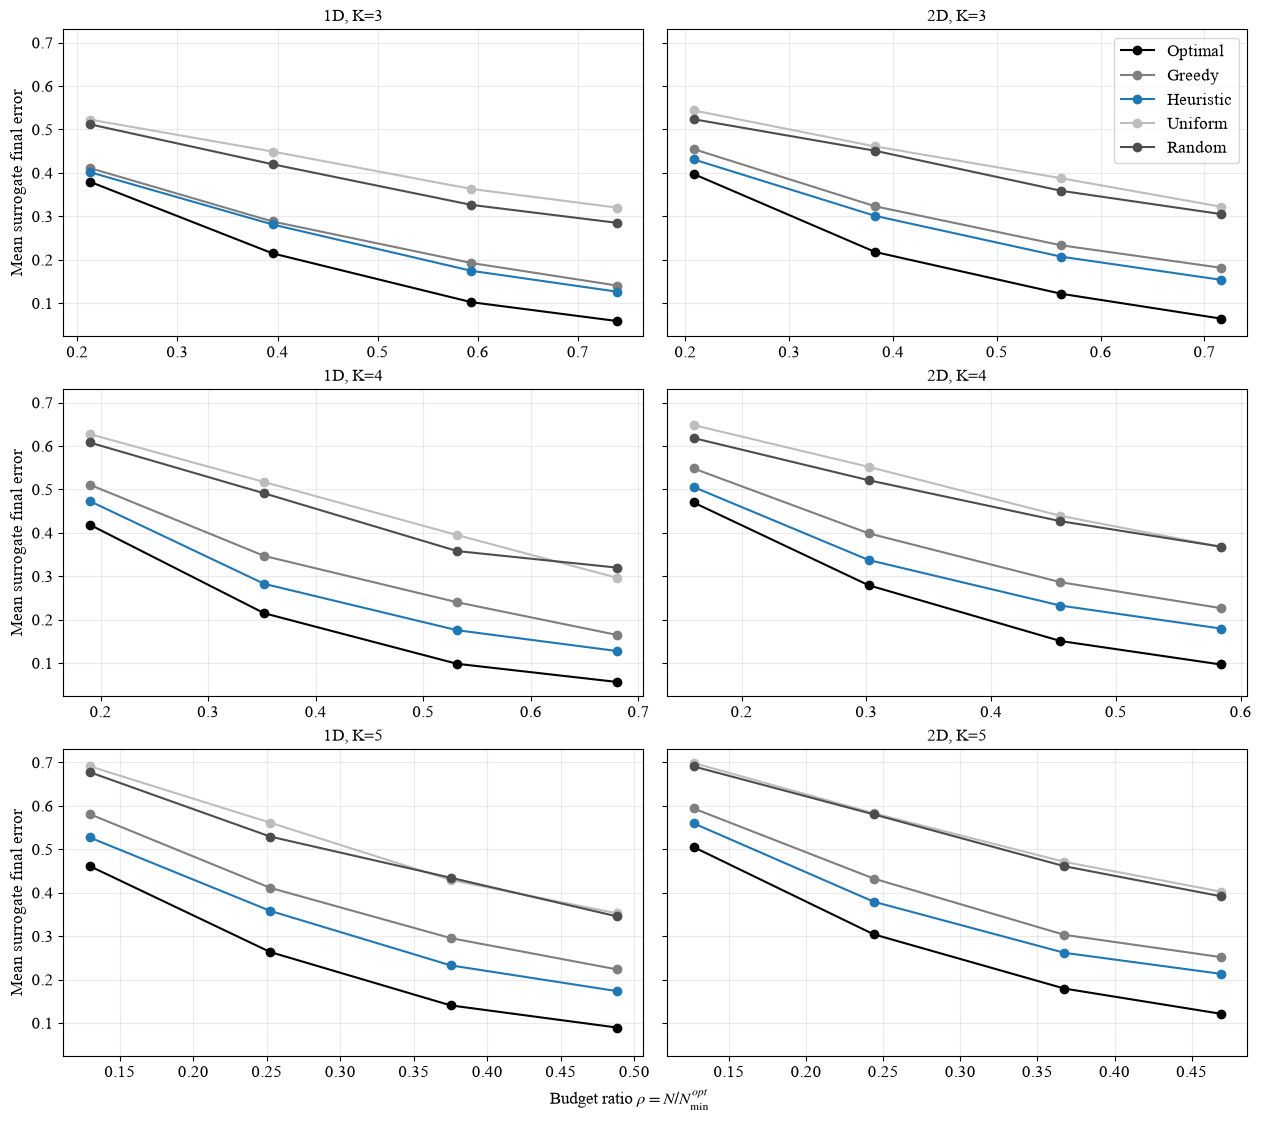

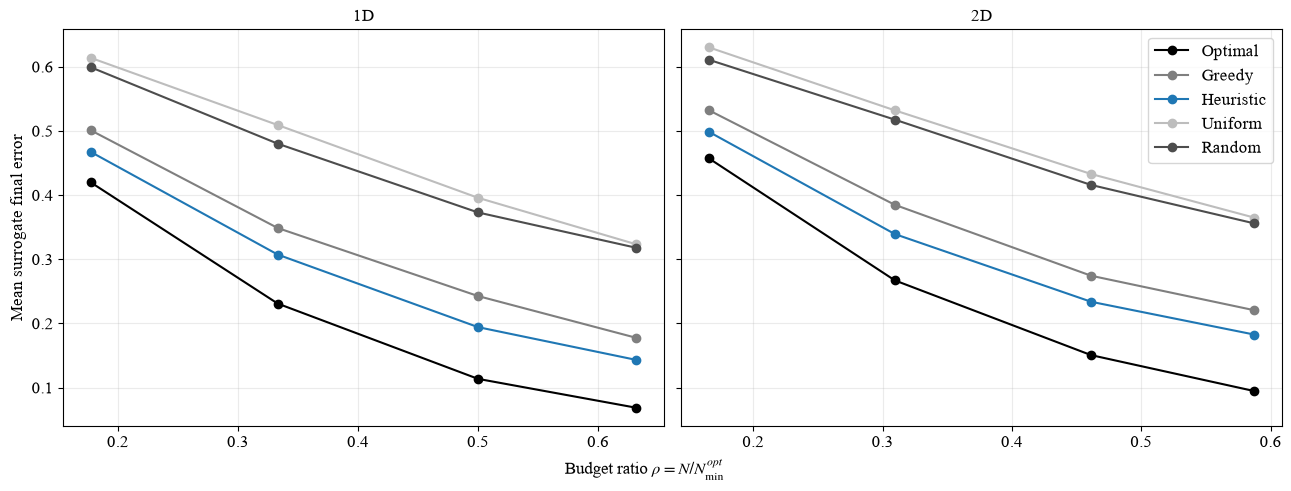

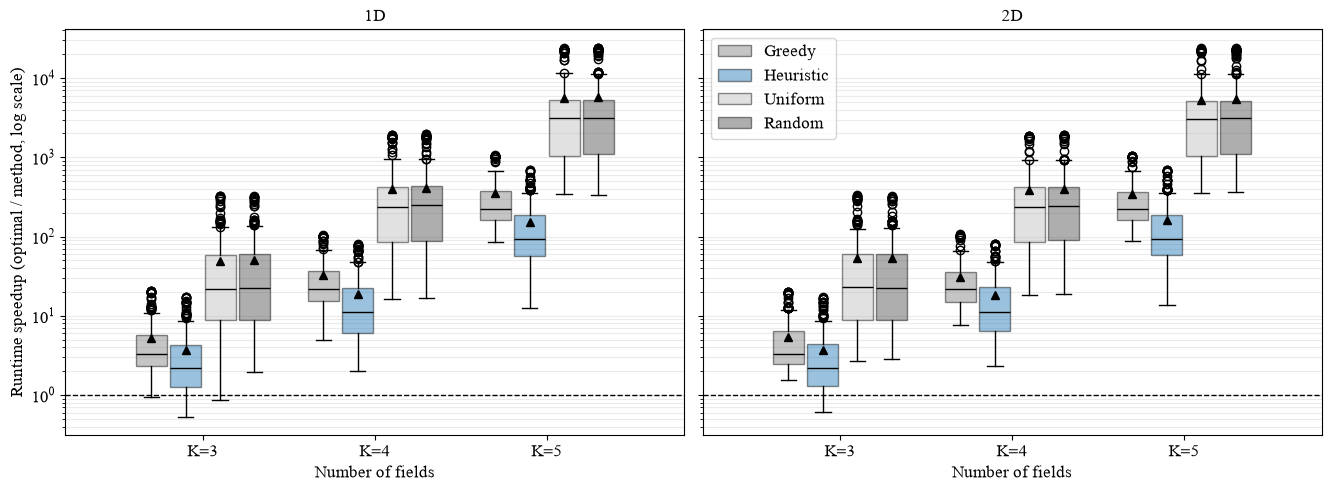

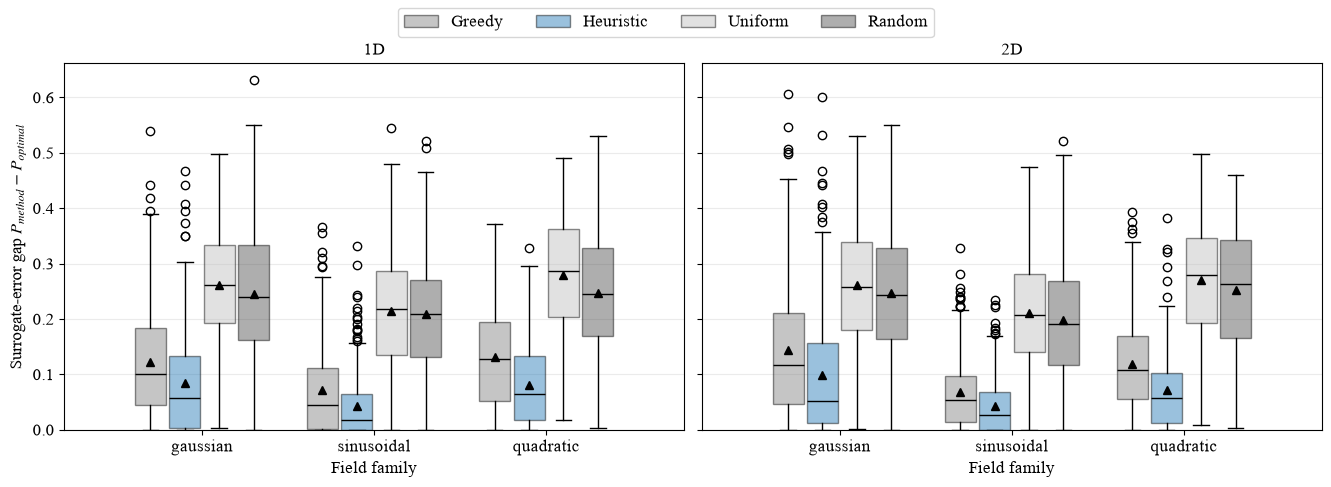

In [13]:
# Close old figures, then reload and apply the shared style.
plt.close("all")
import plot_style
plot_style = importlib.reload(plot_style)
plot_style.configure_plot_style()
# Reload plotting code so an open kernel does not reuse older functions.
comparison_analysis = importlib.reload(comparison_analysis)
# Load saved records when the expensive run cell was intentionally skipped.
if "records_by_dataset" not in globals():
    records_by_dataset = {
        dataset: comparison_analysis.load_paired_results(
            dataset, results_root=RESULTS_ROOT, run_scope=RUN_SCOPE
        )
        for dataset in DATASETS
    }
# Create the four selected figures and save PNG and PDF copies.
for title, figure in comparison_analysis.make_combined_comparison_plots(
    records_by_dataset,  # Paired results for both dimensions.
    results_root=RESULTS_ROOT,  # Base directory for comparison results.
    run_scope=RUN_SCOPE,  # Keeps test and full-run summaries separate.
):
    display(Markdown(f"## {title}"))
    display(figure)
    # Close the Python figure after displaying it to release memory.


## Saved files

The notebook saves detailed tables separately by dimension and puts the side-by-side figures in one combined folder:

```text
results/algorithm_comparison_compact/
├── compact_benchmark_1d_results_<test|full>/tables/
├── compact_benchmark_2d_results_<test|full>/tables/
└── results_summary_compact_benchmark_1d_compact_benchmark_2d_<test|full>/figures/
    ├── mean_error_curves.*
    ├── runtime_speedup.*
    └── error_gap_by_field_family.*
```

